<a href="https://colab.research.google.com/github/Khadeeja-beevi12/End-Project/blob/main/Module_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ABC Company Employee Data Analysis
**Module 1 – End Project**

This notebook analyzes the employee dataset (458 rows and 9 columns) to explore team distribution, position distribution, age groups, salary expenditure, and the relationship between age and salary.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [2]:
# Download the Google Sheet as CSV and save it as employee_data.csv beside this notebook.
df = pd.read_csv("ABC Company.xlsx - Sheet1.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumn names:", df.columns.tolist())
df.info()


Dataset shape: (458, 9)


,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,06-Feb,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,06-Jun,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,06-May,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,06-May,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,06-Oct,231,NaN,5000000.0


\nColumn names: ['Name', 'Team', 'Number', 'Position', 'Age', 'Height', 'Weight', 'College', 'Salary']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 458 entries, 0 to 457
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      458 non-null    object 
 1   Team      458 non-null    object 
 2   Number    458 non-null    int64  
 3   Position  458 non-null    object 
 4   Age       458 non-null    int64  
 5   Height    458 non-null    object 
 6   Weight    458 non-null    int64  
 7   College   374 non-null    object 
 8   Salary    447 non-null    float64
dtypes: float64(1), int64(3), object(5)
memory usage: 32.3+ KB


##  Preprocessing
The assignment asks to replace the values in the height column with random integers between 150 and 180. A fixed random seed makes the result reproducible. This intentionally replaces the original height data, so height should not be used for further analysis.

In [5]:
# Standardize column names by removing extra spaces.
df.columns = df.columns.str.strip()

# Make column lookup robust to capitalization and whitespace.
column_lookup = {col.strip().lower(): col for col in df.columns}

# Correct height values if a height column exists.
height_col = column_lookup.get("height")
if height_col:
    rng = np.random.default_rng(42)
    df[height_col] = rng.integers(150, 181, size=len(df))
    print("Height values replaced with random integers from 150 to 180.")
else:
    print("No 'Height' column found; check the dataset column names.")

# Identify columns using case-insensitive matching.
def find_col(name):
    return column_lookup.get(name.lower())

team_col = find_col("team")
position_col = find_col("position")
age_col = find_col("age")
salary_col = find_col("salary")

required = {"Team": team_col, "Position": position_col, "Age": age_col, "Salary": salary_col}
missing = [name for name, col in required.items() if col is None]
if missing:
    raise ValueError(f"Required column(s) not found: {missing}. Actual columns: {df.columns.tolist()}")

# Convert analysis columns to suitable data types.
df[age_col] = pd.to_numeric(df[age_col], errors="coerce")
df[salary_col] = pd.to_numeric(df[salary_col].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")

# Clean text columns and preserve missing values as missing.
for col in [team_col, position_col]:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace("", pd.NA)

print("Duplicate rows:", df.duplicated().sum())
print("\\nMissing values by column:")
display(df.isna().sum().to_frame("Missing values"))

# We retain rows with missing salary for employee-count analyses,
# but exclude missing salary values from salary calculations.
display(df.head())


Height values replaced with random integers from 150 to 180.
Duplicate rows: 0
\nMissing values by column:


,Missing values
Name,0
Team,0
Number,0
Position,0
Age,0
Height,0
Weight,0
College,84
Salary,11


,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,152,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,173,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,170,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,163,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,163,231,NaN,5000000.0


##Analysis Task 1
Team distribution and percentage split

,Employee Count,Percentage (%)
Team,,
New Orleans Pelicans,19,4.15
Memphis Grizzlies,18,3.93
Utah Jazz,16,3.49
Milwaukee Bucks,16,3.49
New York Knicks,16,3.49
Boston Celtics,15,3.28
Los Angeles Clippers,15,3.28
Los Angeles Lakers,15,3.28
Phoenix Suns,15,3.28


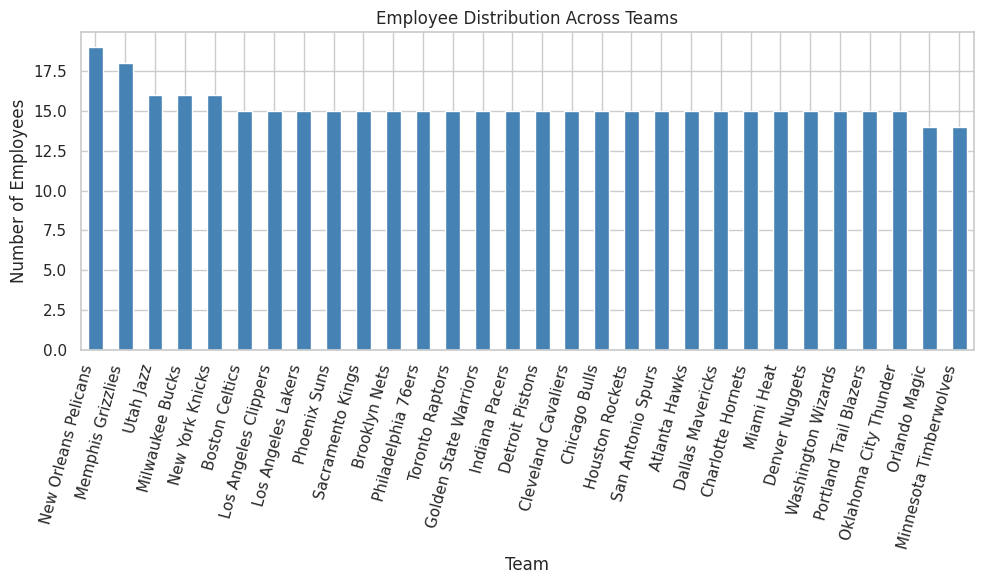

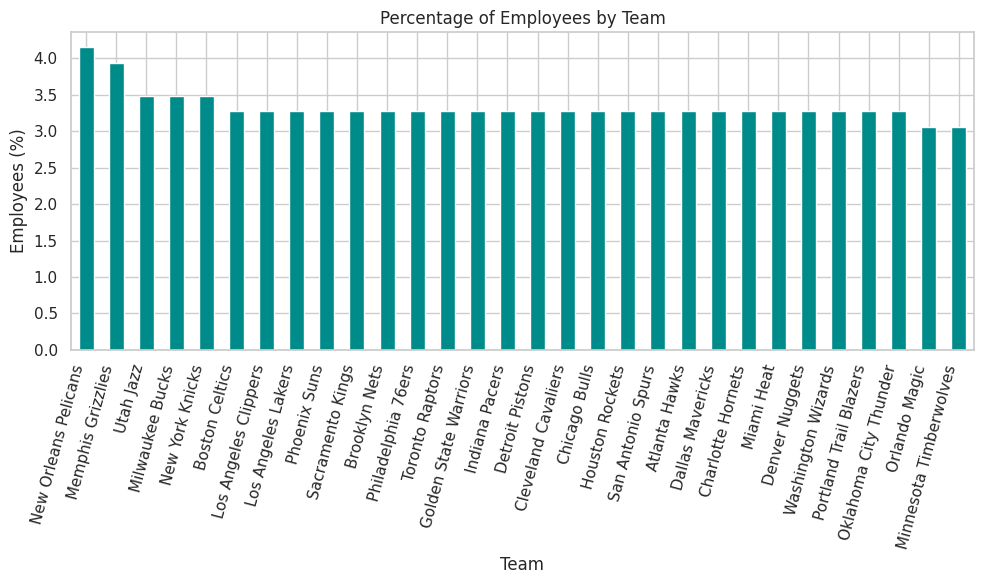

Team with the most employees: New Orleans Pelicans (19 employees; 4.15%).


In [6]:
team_counts = df[team_col].value_counts(dropna=False)
team_percentages = (team_counts / len(df) * 100).round(2)
team_summary = pd.DataFrame({
    "Employee Count": team_counts,
    "Percentage (%)": team_percentages
})
display(team_summary)

ax = team_counts.sort_values(ascending=False).plot(kind="bar", color="steelblue")
ax.set_title("Employee Distribution Across Teams")
ax.set_xlabel("Team")
ax.set_ylabel("Number of Employees")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

ax = team_percentages.sort_values(ascending=False).plot(kind="bar", color="darkcyan")
ax.set_title("Percentage of Employees by Team")
ax.set_xlabel("Team")
ax.set_ylabel("Employees (%)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

largest_team = team_counts.idxmax()
print(f"Team with the most employees: {largest_team} ({team_counts.max()} employees; {team_percentages.loc[largest_team]}%).")


##Analysis Task 2
Employee segregation by position

,Employee Count,Percentage (%)
Position,,
SG,102,22.27
PF,100,21.83
PG,92,20.09
SF,85,18.56
C,79,17.25


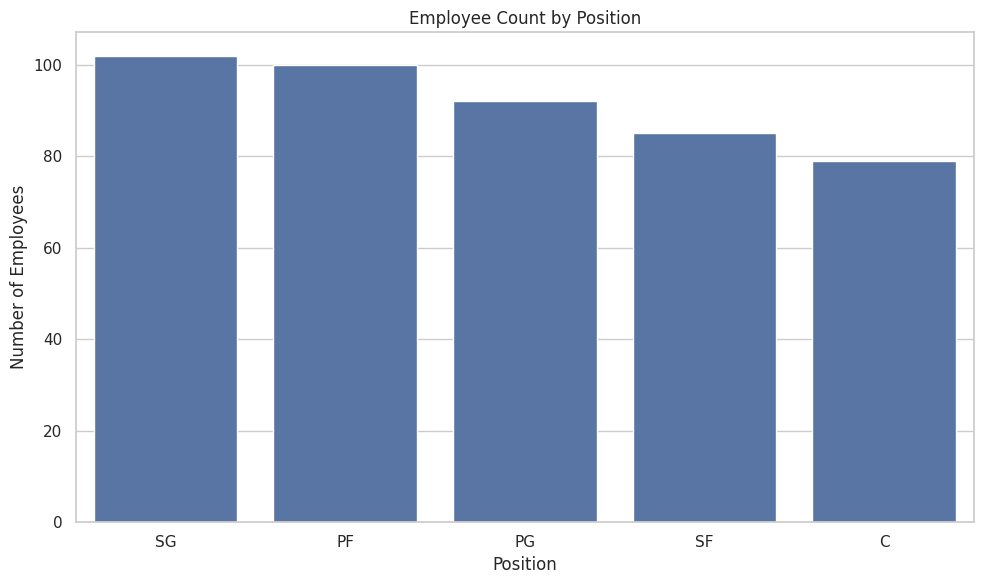

Most common position: SG (102 employees).


In [7]:
position_counts = df[position_col].value_counts(dropna=False)
position_percentages = (position_counts / len(df) * 100).round(2)
position_summary = pd.DataFrame({
    "Employee Count": position_counts,
    "Percentage (%)": position_percentages
})
display(position_summary)

ax = sns.countplot(data=df, x=position_col, order=df[position_col].value_counts().index)
ax.set_title("Employee Count by Position")
ax.set_xlabel("Position")
ax.set_ylabel("Number of Employees")
plt.tight_layout()
plt.show()

most_common_position = position_counts.idxmax()
print(f"Most common position: {most_common_position} ({position_counts.max()} employees).")


##Analysis Task 3
Predominant age group

,Employee Count
Age Group,
10–19,2
20–29,334
30–39,119
40–49,3


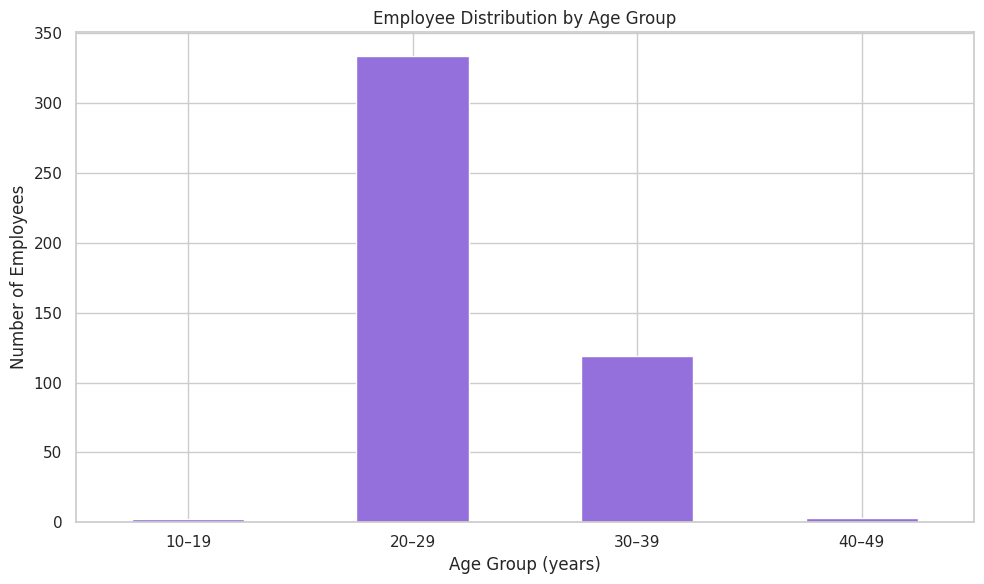

Predominant age group: 20–29 (334 employees).


In [8]:
# Group ages into 10-year bands; right=False makes bands such as 20–29, 30–39.
age_min = int(df[age_col].min())
age_max = int(df[age_col].max())
start = (age_min // 10) * 10
end = ((age_max // 10) + 1) * 10
bins = list(range(start, end + 10, 10))
labels = [f"{b}–{b+9}" for b in bins[:-1]]
df["Age Group"] = pd.cut(df[age_col], bins=bins, labels=labels, right=False, include_lowest=True)

age_group_counts = df["Age Group"].value_counts().sort_index()
display(age_group_counts.rename("Employee Count").to_frame())

ax = age_group_counts.plot(kind="bar", color="mediumpurple")
ax.set_title("Employee Distribution by Age Group")
ax.set_xlabel("Age Group (years)")
ax.set_ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

if age_group_counts.dropna().empty:
    print("No valid age values available for age-group analysis.")
else:
    predominant_age_group = age_group_counts.idxmax()
    print(f"Predominant age group: {predominant_age_group} ({age_group_counts.max()} employees).")


## Analysis Task 4
Highest salary expenditure by team and position

Total salary expenditure by team:


,Total Salary
Team,
Cleveland Cavaliers,106988689.0
Los Angeles Clippers,94854640.0
Oklahoma City Thunder,93765298.0
Golden State Warriors,88868997.0
Chicago Bulls,86783378.0
San Antonio Spurs,84442733.0
New Orleans Pelicans,82750774.0
Miami Heat,82515673.0
Charlotte Hornets,78340920.0


Total salary expenditure by position:


,Total Salary
Position,
C,466377332.0
PG,446848971.0
PF,442560850.0
SF,408020976.0
SG,396976258.0


Highest-spending team-position combinations:


,,Total Salary
Team,Position,
Los Angeles Lakers,SF,31866445.0
Miami Heat,PF,31538671.0
Houston Rockets,SG,28122883.0
Phoenix Suns,PG,28002998.0
Denver Nuggets,SF,27982771.0
Cleveland Cavaliers,PF,27882029.0
New Orleans Pelicans,SG,27489643.0
Sacramento Kings,C,26950230.0
Oklahoma City Thunder,SF,25798862.0


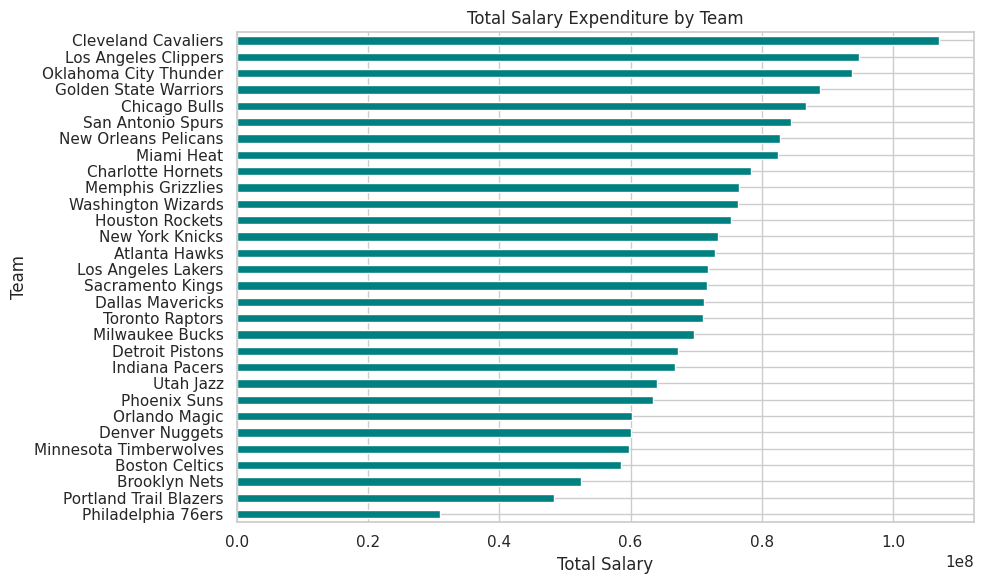

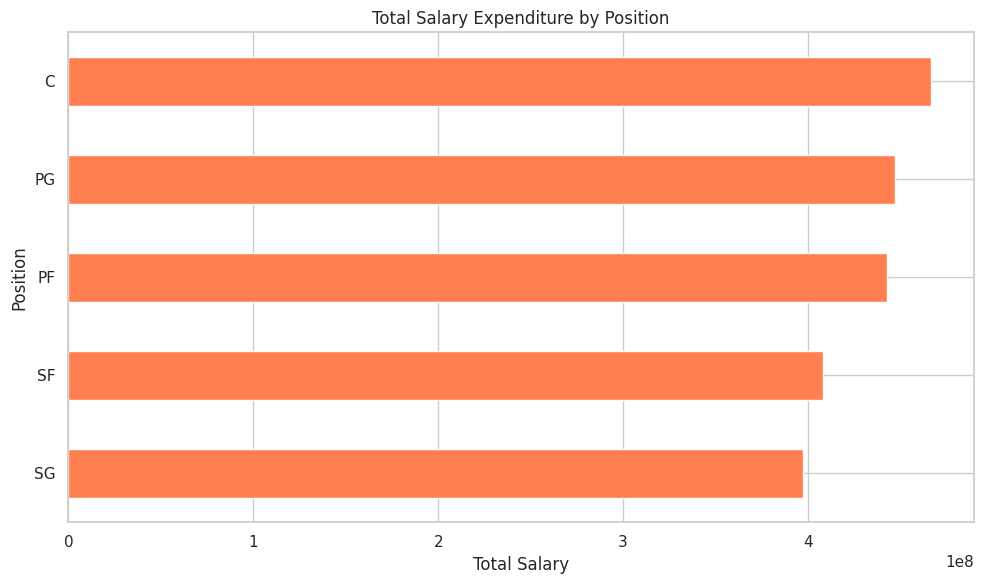

Highest-spending team: Cleveland Cavaliers (total salary 106,988,689).
Highest-spending position: C (total salary 466,377,332).
Highest-spending team-position combination: Los Angeles Lakers — SF (total salary 31,866,445).


In [9]:
salary_df = df.dropna(subset=[salary_col, team_col, position_col]).copy()

team_salary = salary_df.groupby(team_col)[salary_col].sum().sort_values(ascending=False)
position_salary = salary_df.groupby(position_col)[salary_col].sum().sort_values(ascending=False)
team_position_salary = (
    salary_df.groupby([team_col, position_col])[salary_col]
    .sum()
    .sort_values(ascending=False)
)

print("Total salary expenditure by team:")
display(team_salary.to_frame("Total Salary"))
print("Total salary expenditure by position:")
display(position_salary.to_frame("Total Salary"))
print("Highest-spending team-position combinations:")
display(team_position_salary.head(10).to_frame("Total Salary"))

ax = team_salary.sort_values().plot(kind="barh", color="teal")
ax.set_title("Total Salary Expenditure by Team")
ax.set_xlabel("Total Salary")
ax.set_ylabel("Team")
plt.tight_layout()
plt.show()

ax = position_salary.sort_values().plot(kind="barh", color="coral")
ax.set_title("Total Salary Expenditure by Position")
ax.set_xlabel("Total Salary")
ax.set_ylabel("Position")
plt.tight_layout()
plt.show()

if not team_salary.empty:
    print(f"Highest-spending team: {team_salary.idxmax()} (total salary {team_salary.max():,.0f}).")
if not position_salary.empty:
    print(f"Highest-spending position: {position_salary.idxmax()} (total salary {position_salary.max():,.0f}).")
if not team_position_salary.empty:
    top_combo = team_position_salary.index[0]
    print(f"Highest-spending team-position combination: {top_combo[0]} — {top_combo[1]} (total salary {team_position_salary.iloc[0]:,.0f}).")


## Analysis Task 5
Correlation between age and salary

Pearson correlation between age and salary: 0.214


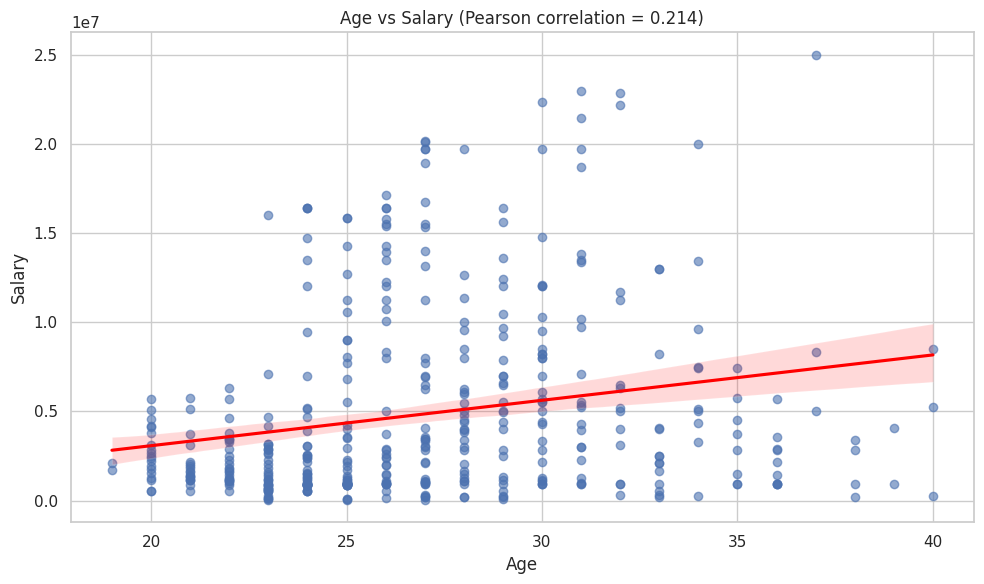

There is a moderate positive linear relationship in this dataset.
Correlation describes association; it does not prove that age causes salary changes.


In [10]:
age_salary = df[[age_col, salary_col]].dropna()
correlation = age_salary[age_col].corr(age_salary[salary_col])
print(f"Pearson correlation between age and salary: {correlation:.3f}")

plt.figure(figsize=(10, 6))
sns.regplot(data=age_salary, x=age_col, y=salary_col,
            scatter_kws={"alpha": 0.6}, line_kws={"color": "red"})
plt.title(f"Age vs Salary (Pearson correlation = {correlation:.3f})")
plt.xlabel("Age")
plt.ylabel("Salary")
plt.tight_layout()
plt.show()

if pd.isna(correlation):
    interpretation = "Correlation could not be calculated from the available data."
elif correlation > 0.5:
    interpretation = "There is a strong positive linear relationship in this dataset."
elif correlation > 0.2:
    interpretation = "There is a moderate positive linear relationship in this dataset."
elif correlation > 0:
    interpretation = "There is a weak positive linear relationship in this dataset."
elif correlation < -0.5:
    interpretation = "There is a strong negative linear relationship in this dataset."
elif correlation < -0.2:
    interpretation = "There is a moderate negative linear relationship in this dataset."
elif correlation < 0:
    interpretation = "There is a weak negative linear relationship in this dataset."
else:
    interpretation = "There is little or no linear relationship in this dataset."
print(interpretation)
print("Correlation describes association; it does not prove that age causes salary changes.")


##Data story
Key findings

In [11]:
# Automatically summarize the key results after the analysis cells have run.
print("DATA STORY")
print("-" * 50)
if not team_counts.empty:
    print(f"Team with the largest workforce: {team_counts.idxmax()} ({team_counts.max()} employees, {team_percentages.loc[team_counts.idxmax()]}%).")
if not position_counts.empty:
    print(f"Most common position: {position_counts.idxmax()} ({position_counts.max()} employees).")
if not age_group_counts.dropna().empty:
    print(f"Predominant age group: {age_group_counts.idxmax()} ({age_group_counts.max()} employees).")
if not team_salary.empty:
    print(f"Largest team salary expenditure: {team_salary.idxmax()} ({team_salary.max():,.0f}).")
if not position_salary.empty:
    print(f"Largest position salary expenditure: {position_salary.idxmax()} ({position_salary.max():,.0f}).")
if not team_position_salary.empty:
    print(f"Highest-spending team-position combination: {team_position_salary.index[0]} ({team_position_salary.iloc[0]:,.0f}).")
print(f"Age-salary correlation: {correlation:.3f}. {interpretation}")
print("\\nUse these computed results to write a short conclusion in your own words. Mention that height was randomized as instructed and is not suitable for substantive interpretation.")


DATA STORY
--------------------------------------------------
Team with the largest workforce: New Orleans Pelicans (19 employees, 4.15%).
Most common position: SG (102 employees).
Predominant age group: 20–29 (334 employees).
Largest team salary expenditure: Cleveland Cavaliers (106,988,689).
Largest position salary expenditure: C (466,377,332).
Highest-spending team-position combination: ('Los Angeles Lakers', 'SF') (31,866,445).
Age-salary correlation: 0.214. There is a moderate positive linear relationship in this dataset.
\nUse these computed results to write a short conclusion in your own words. Mention that height was randomized as instructed and is not suitable for substantive interpretation.


In [12]:
df.to_csv("employee_data_cleaned.csv", index=False)
print("Saved cleaned dataset as employee_data_cleaned.csv")


Saved cleaned dataset as employee_data_cleaned.csv
